## Homework 4

### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split, KFold

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

numerical = ['annual_income', 'number_of_courses_viewed', 'lead_score', 'interaction_count']
categorical = ['lead_source', 'industry', 'employment_status', 'location']

for n in numerical:
    df[n] = df[n].fillna(0.0)

for c in categorical:
    df[c] = df[c].fillna('NA')

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [3]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

for n in numerical:
    print(f'{n} %.3f' % roc_auc_score(y_train, df_train[n]))

print('\nQ1. Answer: lead_score')

annual_income 0.608
number_of_courses_viewed 0.723
lead_score 0.788
interaction_count 0.765

Q1. Answer: lead_score


### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [4]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[numerical + categorical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[numerical + categorical].to_dict(orient='records')
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
converted_decision = (y_pred >= 0.5)

df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = converted_decision.astype(int)
df_pred['actual'] = y_val
df_pred['correct'] = df_pred.prediction == df_pred.actual

fpr, tpr, thresholds = roc_curve(y_val, y_pred)
print(f"%.3f" % auc(fpr, tpr))

print('\nQ2. Answer: 0.732')

0.732

Q2. Answer: 0.732


### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83


Q3. Answer: 0.63


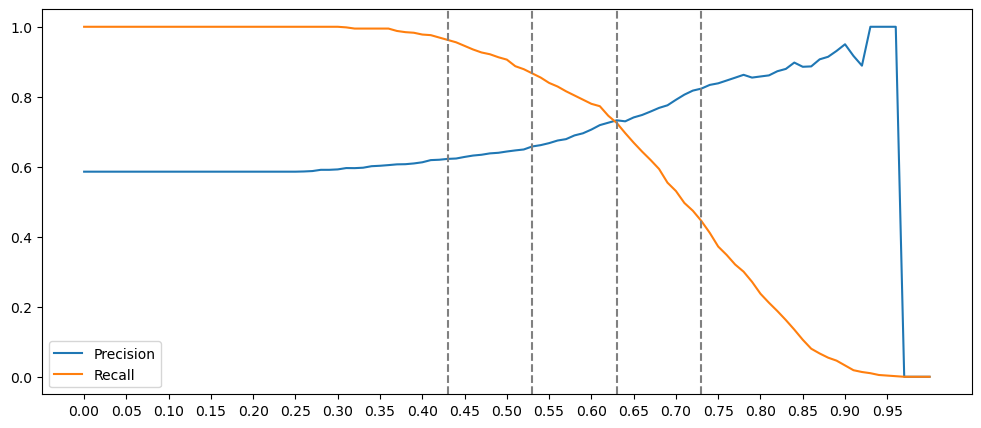

In [5]:
scores = []
thresholds = np.linspace(0, 1, 101)
 
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)
  
for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)   

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()   

    # p = tp / (tp + fp)
    p = precision_score(y_val, predict_positive, zero_division=0)
    
    # r = tp / (tp + fn)
    r = recall_score(y_val, predict_positive, zero_division=0)

    scores.append((t, tp, fp, fn, tn, p, r))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn', 'p', 'r']
df_scores = pd.DataFrame(scores, columns=columns)

plt.figure(figsize=(12, 5))
plt.plot(df_scores['threshold'], df_scores['p'], label='Precision')
plt.plot(df_scores['threshold'], df_scores['r'], label='Recall')
plt.axvline(0.43, color='gray', linestyle='--')
plt.axvline(0.53, color='gray', linestyle='--')
plt.axvline(0.63, color='gray', linestyle='--')
plt.axvline(0.73, color='gray', linestyle='--')
plt.xticks(np.arange(0, 1, 0.05))
plt.legend()

print('\nQ3. Answer: 0.63')

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [6]:
for t in np.linspace(0, 1, 101):
    predict_positive = (y_pred >= t)

    # p = tp / (tp + fp)
    # r = tp / (tp + fn)
    # f1_score = 2 * (p * r) / (p + r)
    
    f1 = f1_score(y_val, predict_positive, zero_division=0)

    print(f'%.2f - %.4f' % (t, f1))

print('\nQ4. Answer: 0.41')

0.00 - 0.7390
0.01 - 0.7390
0.02 - 0.7390
0.03 - 0.7390
0.04 - 0.7390
0.05 - 0.7390
0.06 - 0.7390
0.07 - 0.7390
0.08 - 0.7390
0.09 - 0.7390
0.10 - 0.7390
0.11 - 0.7390
0.12 - 0.7390
0.13 - 0.7390
0.14 - 0.7390
0.15 - 0.7390
0.16 - 0.7390
0.17 - 0.7390
0.18 - 0.7390
0.19 - 0.7390
0.20 - 0.7390
0.21 - 0.7390
0.22 - 0.7390
0.23 - 0.7390
0.24 - 0.7390
0.25 - 0.7390
0.26 - 0.7394
0.27 - 0.7404
0.28 - 0.7432
0.29 - 0.7432
0.30 - 0.7441
0.31 - 0.7466
0.32 - 0.7455
0.33 - 0.7465
0.34 - 0.7498
0.35 - 0.7508
0.36 - 0.7523
0.37 - 0.7519
0.38 - 0.7513
0.39 - 0.7524
0.40 - 0.7535
0.41 - 0.7576
0.42 - 0.7563
0.43 - 0.7560
0.44 - 0.7547
0.45 - 0.7548
0.46 - 0.7543
0.47 - 0.7531
0.48 - 0.7542
0.49 - 0.7525
0.50 - 0.7527
0.51 - 0.7482
0.52 - 0.7469
0.53 - 0.7482
0.54 - 0.7461
0.55 - 0.7438
0.56 - 0.7443
0.57 - 0.7411
0.58 - 0.7423
0.59 - 0.7406
0.60 - 0.7413
0.61 - 0.7451
0.62 - 0.7357
0.63 - 0.7290
0.64 - 0.7127
0.65 - 0.7031
0.66 - 0.6917
0.67 - 0.6817
0.68 - 0.6699
0.69 - 0.6468
0.70 - 0.6353
0.71 -

### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [7]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print(f'Q5. Answer: %.3f' % np.std(scores))

Q5. Answer: 0.007


### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [8]:
for C in [0.000001, 0.001, 1]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print(f'{C} - mean:%.3f | std:%.3f' % (np.mean(scores), np.std(scores)))

print('\nQ6. Answer: 0.001')

1e-06 - mean:0.617 | std:0.019
0.001 - mean:0.749 | std:0.010
1 - mean:0.732 | std:0.007

Q6. Answer: 0.001
